# Aula 14: Interpolação Polinomial: Newton

## Ideia

Dados $n+1$ pontos com nós distintos $(x_0,y_0),\ldots,(x_n,y_n)$, queremos um polinômio $p_n(x)$ de grau no máximo $n$ que satisfaça

$$p_n(x_i)=y_i,\qquad i=0,\ldots,n.$$

Assim como a forma de Lagrange, a **forma de Newton** constrói o mesmo polinômio interpolador, mas utiliza **diferenças divididas** para obter seus coeficientes.

## Forma de Newton

$$p_n(t)=d_0+d_1(t-x_0)+d_2(t-x_0)(t-x_1)+\cdots+d_n\prod_{j=0}^{n-1}(t-x_j)$$

Os coeficientes $d_k$ são calculados por diferenças divididas:

$$f[x_i]=y_i,\qquad f[x_i,\ldots,x_{i+k}]=\frac{f[x_{i+1},\ldots,x_{i+k}]-f[x_i,\ldots,x_{i+k-1}]}{x_{i+k}-x_i}.$$

Os coeficientes são $d_k=f[x_0,\ldots,x_k]$.

## Algoritmo: Cálculo de $p_n(t)$

```text
Entrada:
    x = vetor com n+1 nós de interpolação
    y = vetor com n+1 valores correspondentes
    t = ponto em que queremos avaliar o polinômio

Para i de 0 até n faça
    d[i] = y[i]
Fim-Para

Para j de 1 até n faça
    Para i de n até j (passo -1) faça
        d[i] = (d[i] - d[i-1]) / (x[i] - x[i-j])
    Fim-Para
Fim-Para

p = 0
Para k de 0 até n faça
    produto = 1
    Para j de 0 até k-1 faça
        produto = produto * (t - x[j])
    Fim-Para
    p = p + d[k] * produto
Fim-Para

Retorne p
```

A primeira parte calcula os coeficientes $d$; a segunda avalia o polinômio diretamente em $t$.

In [ ]:
def newton(x, y, t):
    """Avalia o polinômio interpolador de Newton no ponto t."""
    n = len(x) - 1
    d = y.copy()

    for j in range(1, n + 1):
        for i in range(n, j - 1, -1):
            d[i] = (d[i] - d[i - 1]) / (x[i] - x[i - j])

    p = 0
    for k in range(n + 1):
        produto = 1
        for j in range(k):
            produto = produto * (t - x[j])
        p = p + d[k] * produto

    return p

In [7]:
import numpy as np
import matplotlib.pyplot as plt


def grafico(x, y, titulo, t=None):
    """Desenha o polinômio e os nós; usa NumPy apenas no linspace."""
    margem = max((max(x) - min(x)) * 0.15, 0.4)
    grade = np.linspace(min(x) - margem, max(x) + margem, 400)
    valores = [newton(x, y, ponto) for ponto in grade]

    plt.figure(figsize=(8, 4.5))
    plt.plot(grade, valores, label="Polinômio interpolador")
    plt.scatter(x, y, s=60, label="Pontos conhecidos", zorder=3)
    if t is not None:
        valor = newton(x, y, t)
        plt.scatter([t], [valor], s=75, marker="x",
                    label=f"p({t}) = {valor:.4g}", zorder=4)
    plt.title(titulo)
    plt.xlabel("x")
    plt.ylabel("p(x)")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

## Exemplo 1: Tabela de diferenças divididas 

Considere os cinco pontos:

| $x$ | $-1$ | $0$ | $1$ | $2$ | $3$ |
|---|---:|---:|---:|---:|---:|
| $f(x)$ | $1$ | $1$ | $0$ | $-1$ | $-2$ |

A tabela de diferenças divididas fornece os coeficientes:

$$d_0=1,\quad d_1=0,\quad d_2=-\frac12,\quad d_3=\frac16,\quad d_4=-\frac1{24}.$$

Portanto,

$$p_4(t)=1-\frac12(t+1)t+\frac16(t+1)t(t-1)-\frac1{24}(t+1)t(t-1)(t-2).$$

Vamos avaliar o polinômio em $t=0{,}5$ e visualizar os cinco pontos.

p(0.5) = 0.5390625
Valores nos nós: [1.0, 1.0, 0.0, -1.0, -2.0]


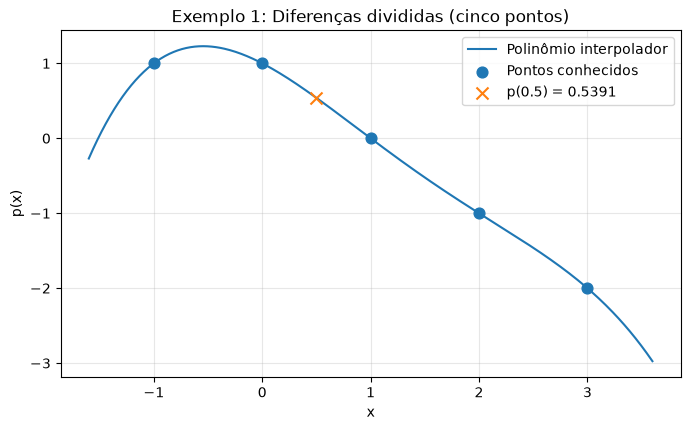

In [8]:
x1 = [-1, 0, 1, 2, 3]
y1 = [1, 1, 0, -1, -2]
print("p(0.5) =", newton(x1, y1, 0.5))
print("Valores nos nós:", [newton(x1, y1, xi) for xi in x1])
grafico(x1, y1, "Exemplo 1: Diferenças divididas (cinco pontos)", t=0.5)

## Exemplo 2: Forma de Newton 

Considere os pontos:

| $x$ | $-1$ | $0$ | $2$ |
|---|---:|---:|---:|
| $f(x)$ | $4$ | $1$ | $-1$ |

As diferenças divididas são:

$$d_0=4,\qquad d_1=\frac{1-4}{0-(-1)}=-3,$$

$$f[0,2]=\frac{-1-1}{2-0}=-1,\qquad d_2=\frac{-1-(-3)}{2-(-1)}=\frac23.$$

Logo,

$$p_2(t)=4-3(t+1)+\frac23(t+1)t$$

$$\boxed{p_2(t)=1-\frac73t+\frac23t^2}.$$

É o **mesmo polinômio** obtido com Lagrange para esses pontos.

p(1) = -0.6666666666666667
Valores nos nós: [4.0, 1.0, -1.0]


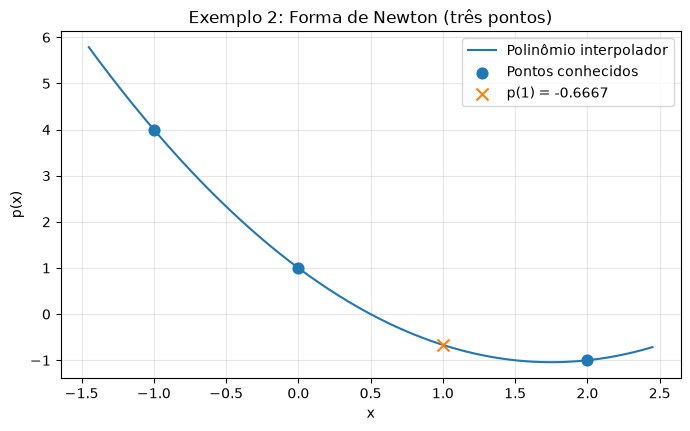

In [9]:
x2 = [-1, 0, 2]
y2 = [4, 1, -1]
print("p(1) =", newton(x2, y2, 1))
print("Valores nos nós:", [newton(x2, y2, xi) for xi in x2])
grafico(x2, y2, "Exemplo 2: Forma de Newton (três pontos)", t=1)

## Exercício: Interpolação de Newton

Utilize os mesmos pontos do exercício de Lagrange:

| $x$ | $0$ | $1$ | $3$ |
|---|---:|---:|---:|
| $f(x)$ | $2$ | $3$ | $11$ |

1. Calcule as diferenças divididas e identifique $d_0,d_1,d_2$.
2. Escreva o polinômio na forma de Newton.
3. Verifique os valores nos nós.
4. Calcule $p_2(2)$.

**Resolução:**

$$d_0=2,\qquad d_1=\frac{3-2}{1-0}=1,\qquad f[1,3]=\frac{11-3}{3-1}=4,$$

$$d_2=\frac{4-1}{3-0}=1.$$

$$p_2(t)=2+t+t(t-1)=\boxed{t^2+2}.$$

$$p_2(0)=2,\quad p_2(1)=3,\quad p_2(3)=11,\quad \boxed{p_2(2)=6}.$$


p(0) = 2 (esperado: 2)
p(1) = 3 (esperado: 3)
p(3) = 11 (esperado: 11)
p(2) = 6.0


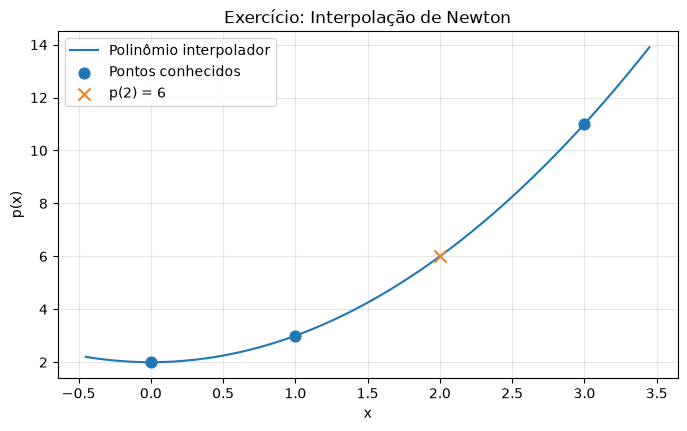

In [10]:
x_ex = [0, 1, 3]
y_ex = [2, 3, 11]
for xi, yi in zip(x_ex, y_ex):
    print(f"p({xi}) = {newton(x_ex, y_ex, xi):.4g} (esperado: {yi})")
print("p(2) =", newton(x_ex, y_ex, 2))
grafico(x_ex, y_ex, "Exercício: Interpolação de Newton", t=2)

## Exemplo adicional: Interpolação com vários pontos

Considere **seis pontos**:

| $x$ | $-2$ | $-1$ | $0$ | $1$ | $2$ | $3$ |
|---|---:|---:|---:|---:|---:|---:|
| $f(x)$ | $3$ | $0$ | $1$ | $2$ | $1$ | $4$ |

O polinômio interpolador tem grau **no máximo 5**. A forma de Newton permite avaliar esse polinômio sem expandi-lo algebricamente. Observe no gráfico como a curva passa por todos os nós.

p(0.5) = 1.7421875
Valores nos nós: [3.0, 0.0, 1.0, 2.0, 1.0, 4.0]


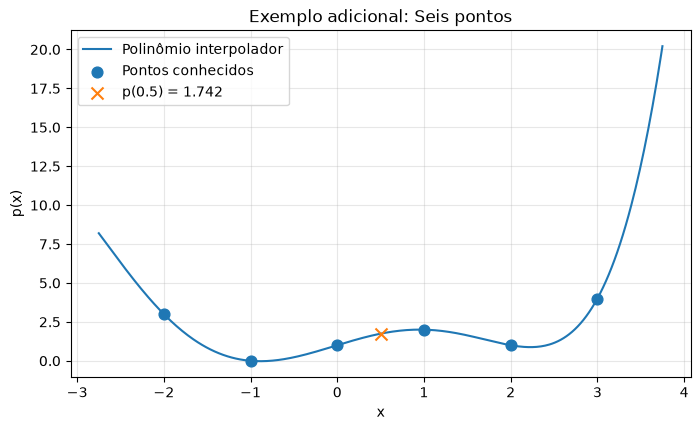

In [11]:
x_varios = [-2, -1, 0, 1, 2, 3]
y_varios = [3, 0, 1, 2, 1, 4]
print("p(0.5) =", newton(x_varios, y_varios, 0.5))
print("Valores nos nós:", [newton(x_varios, y_varios, xi) for xi in x_varios])
grafico(x_varios, y_varios, "Exemplo adicional: Seis pontos", t=0.5)